# UCI Heart Failure Clinical Records EDA
A new notebook; the original empty uci_heart_failure.ipynb remains untouched. This cohort contains people with existing heart failure. DEATH_EVENT is mortality observed during follow-up, not general-population heart-failure diagnosis. Analyze time as follow-up duration, but never include it in predictive features.

## 1-5. Imports, paths, dimensions, schema, missingness, duplicates, target distribution and numeric summary

Shape: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


,column,dtype,unique,missing
age,age,float64,48,0
anaemia,anaemia,int64,2,0
creatinine_phosphokinase,creatinine_phosphokinase,int64,208,0
diabetes,diabetes,int64,2,0
ejection_fraction,ejection_fraction,int64,17,0
high_blood_pressure,high_blood_pressure,int64,2,0
platelets,platelets,float64,176,0
serum_creatinine,serum_creatinine,float64,40,0
serum_sodium,serum_sodium,int64,27,0
sex,sex,int64,2,0


Duplicate rows: 0


,missing_count,missing_percent
age,0,0.0
anaemia,0,0.0
creatinine_phosphokinase,0,0.0
diabetes,0,0.0
ejection_fraction,0,0.0
high_blood_pressure,0,0.0
platelets,0,0.0
serum_creatinine,0,0.0
serum_sodium,0,0.0
sex,0,0.0


,count,percent
DEATH_EVENT,,
0,203,67.892977
1,96,32.107023


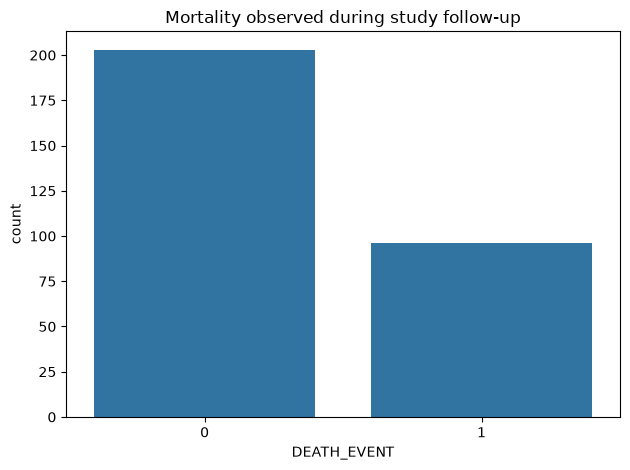

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
age,299.0,60.837237,11.900919,40.0,40.00,42.9,51.0,60.0,70.0,82.1,90.080,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.00,0.0,0.0,0.0,1.0,1.0,1.000,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,47.00,59.0,116.5,250.0,582.0,2263.0,5222.460,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.00,0.0,0.0,0.0,1.0,1.0,1.000,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,16.96,20.0,30.0,38.0,45.0,60.0,62.060,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.00,0.0,0.0,0.0,1.0,1.0,1.000,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,61780.00,131800.0,212500.0,262000.0,303500.0,422500.0,544560.000,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.60,0.7,0.9,1.1,1.4,3.0,6.114,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,123.94,130.0,134.0,137.0,140.0,144.0,145.000,148.0
sex,299.0,0.648829,0.478136,0.0,0.00,0.0,0.0,1.0,1.0,1.0,1.000,1.0


In [1]:
from pathlib import Path
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu
root=Path.cwd().resolve()
while not (root/'src').is_dir():
    if root.parent==root: raise FileNotFoundError('Open from ml-service')
    root=root.parent
path=root/'data/raw/biomarkers/uci_heart_failure/Heart_failure_clinical_records_dataset.csv'
out=root/'artifacts/eda/uci_heart_failure'; plots=out/'plots'
out.mkdir(parents=True,exist_ok=True); plots.mkdir(parents=True,exist_ok=True)
if not path.exists(): raise FileNotFoundError(f'Place source CSV at {path}')
df=pd.read_csv(path); df.columns=df.columns.str.strip()
target='DEATH_EVENT'
if target not in df: raise ValueError('Missing DEATH_EVENT target')
print('Shape:',df.shape); display(df.head())
schema=pd.DataFrame({'column':df.columns,'dtype':df.dtypes.astype(str),'unique':df.nunique().values,'missing':df.isna().sum().values})
schema.to_csv(out/'schema.csv',index=False); display(schema)
print('Duplicate rows:',int(df.duplicated().sum()))
quality=pd.DataFrame({'missing_count':df.isna().sum(),'missing_percent':100*df.isna().mean()})
quality.to_csv(out/'missing_values.csv'); display(quality)
counts=df[target].value_counts().sort_index()
target_summary=pd.DataFrame({'count':counts,'percent':100*counts/len(df)})
target_summary.to_csv(out/'target_distribution.csv'); display(target_summary)
sns.countplot(data=df,x=target); plt.title('Mortality observed during study follow-up'); plt.tight_layout()
plt.savefig(plots/'target_distribution.png',dpi=160); plt.show()
numeric=df.select_dtypes(include=np.number).columns.tolist()
stats=df[numeric].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T
stats.to_csv(out/'numeric_descriptive_statistics.csv'); display(stats)


## 6-11. Age, renal/electrolyte biomarkers, CPK, platelets, ejection fraction, binary features and outcome-group summaries

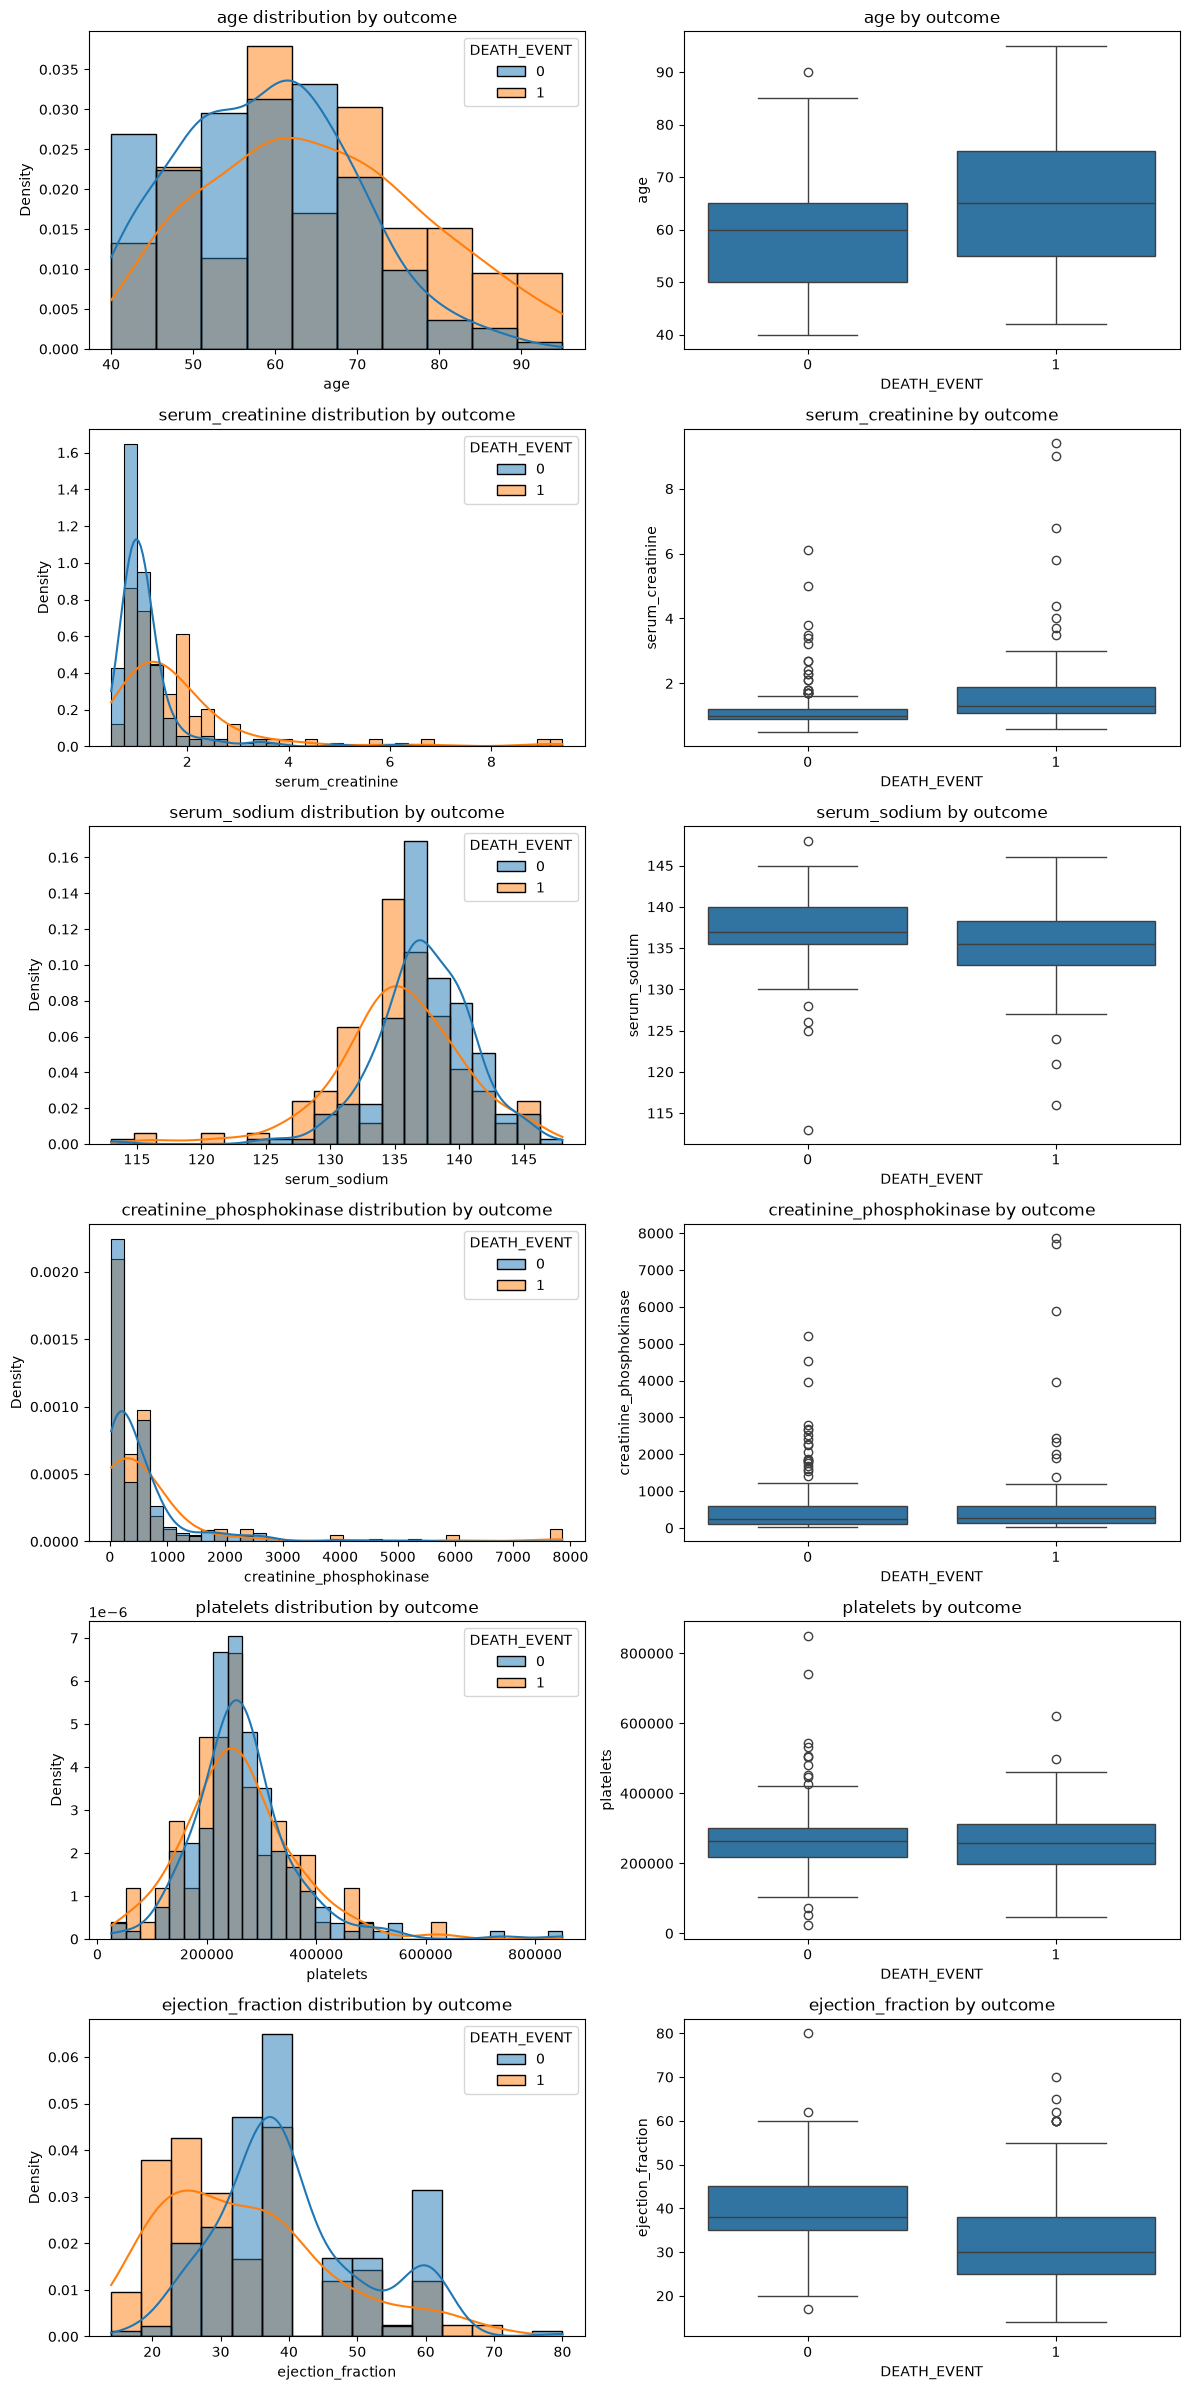

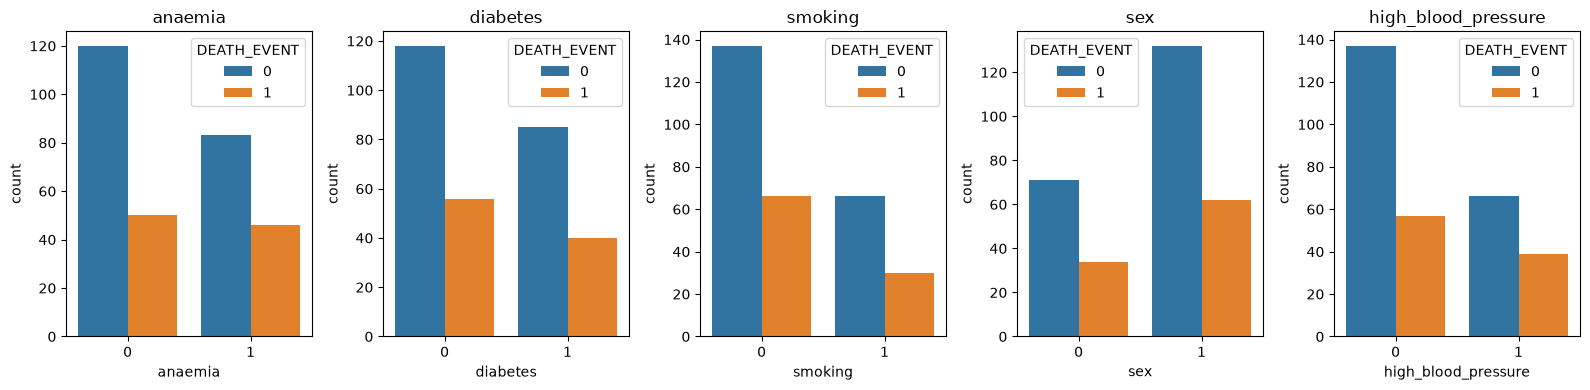

age                           anaemia                   \
                  mean median        std count      mean median       std   
DEATH_EVENT                                                                 
0            58.761906   60.0  10.637890   203  0.408867    0.0  0.492840   
1            65.225698   65.0  13.228313    96  0.479167    0.0  0.502188   

                  creatinine_phosphokinase         ...   smoking        \
            count                     mean median  ...       std count   
DEATH_EVENT                                        ...                   
0             203               540.054187  245.0  ...  0.469579   203   
1              96               670.197917  259.0  ...  0.465946    96   

                   time                         DEATH_EVENT                    
                   mean median        std count        mean median  std count  
DEATH_EVENT                                                                    
0            158.339901  172.0  67.742872   203         0.0    0.0  0.0   203  
1             70.885417   44.5  62.378281    96         1.0    1.0  0.0    96  

[2 rows x 52 columns]

In [2]:
continuous=['age','serum_creatinine','serum_sodium','creatinine_phosphokinase','platelets','ejection_fraction']
fig,axes=plt.subplots(len(continuous),2,figsize=(12,4*len(continuous)))
for i,col in enumerate(continuous):
    sns.histplot(data=df,x=col,hue=target,kde=True,stat='density',common_norm=False,ax=axes[i,0])
    sns.boxplot(data=df,x=target,y=col,ax=axes[i,1])
    axes[i,0].set_title(f'{col} distribution by outcome'); axes[i,1].set_title(f'{col} by outcome')
plt.tight_layout();plt.savefig(plots/'continuous_by_outcome.png',dpi=160);plt.show()
binary=['anaemia','diabetes','smoking','sex','high_blood_pressure']
fig,axes=plt.subplots(1,len(binary),figsize=(16,4))
for ax,col in zip(axes,binary):
    sns.countplot(data=df,x=col,hue=target,ax=ax);ax.set_title(col)
    pd.crosstab(df[col],df[target]).to_csv(out/f'{col}_by_outcome.csv')
plt.tight_layout();plt.savefig(plots/'binary_by_outcome.png',dpi=160);plt.show()
grouped=df.groupby(target)[numeric].agg(['mean','median','std','count'])
grouped.to_csv(out/'feature_summary_by_outcome.csv');display(grouped)


## 12-14. Correlation, outlier review, and follow-up duration analysis (time excluded from model inputs)

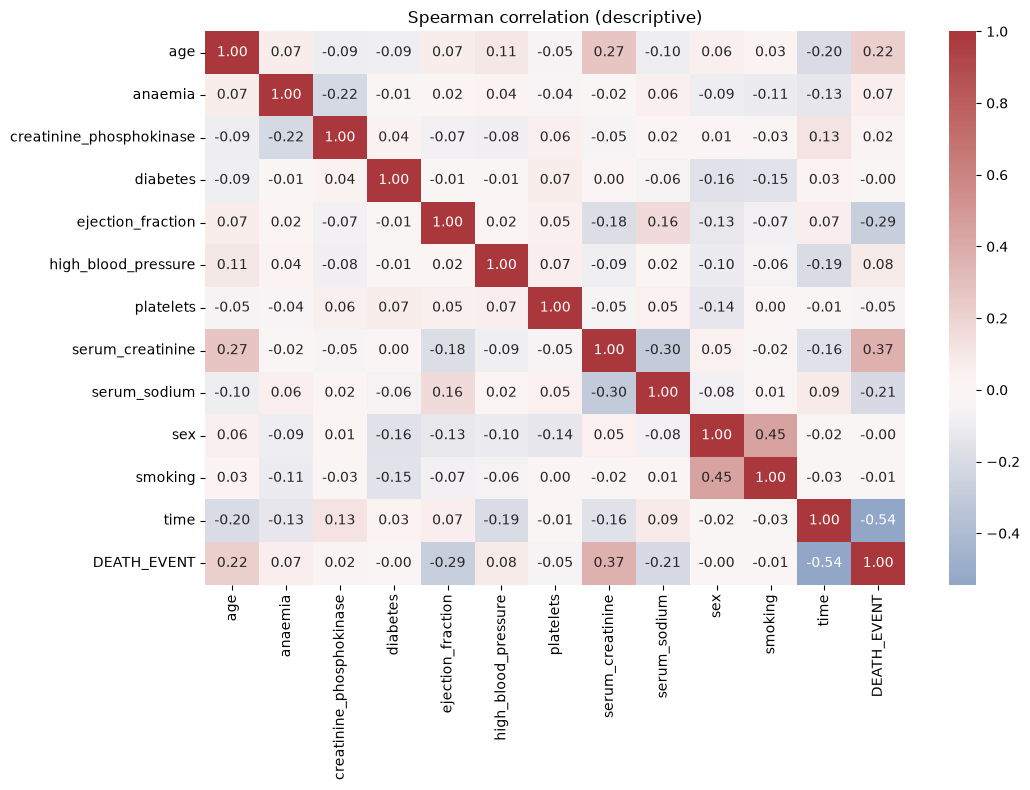

,feature,lower_fence,upper_fence,outlier_count
2,creatinine_phosphokinase,-581.75,1280.25,29
7,serum_creatinine,0.15,2.15,29
6,platelets,76000.00,440000.00,21
8,serum_sodium,125.00,149.00,4
4,ejection_fraction,7.50,67.50,2
3,diabetes,-1.50,2.50,0
1,anaemia,-1.50,2.50,0
0,age,22.50,98.50,0
5,high_blood_pressure,-1.50,2.50,0
9,sex,-1.50,2.50,0


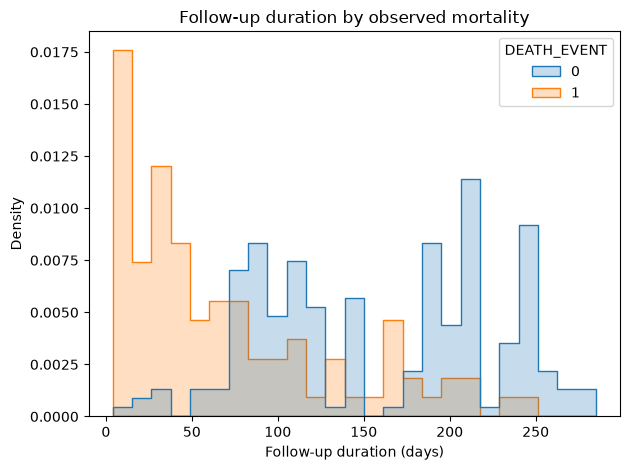

,count,mean,std,min,25%,50%,75%,max
DEATH_EVENT,,,,,,,,
0,203.0,158.339901,67.742872,12.0,95.0,172.0,213.00,285.0
1,96.0,70.885417,62.378281,4.0,25.5,44.5,102.25,241.0


In [3]:
corr=df[numeric].corr(method='spearman')
plt.figure(figsize=(11,8))
sns.heatmap(corr,cmap='vlag',center=0,annot=True,fmt='.2f')
plt.title('Spearman correlation (descriptive)');plt.tight_layout();plt.savefig(plots/'spearman_correlation.png',dpi=160);plt.show()
corr.to_csv(out/'spearman_correlation.csv')
rows=[]
for col in numeric:
    q1,q3=df[col].quantile([.25,.75]);iqr=q3-q1
    rows.append({'feature':col,'lower_fence':q1-1.5*iqr,'upper_fence':q3+1.5*iqr,
                 'outlier_count':int(((df[col]<q1-1.5*iqr)|(df[col]>q3+1.5*iqr)).sum())})
outliers=pd.DataFrame(rows).sort_values('outlier_count',ascending=False)
outliers.to_csv(out/'outlier_summary.csv',index=False);display(outliers)
if 'time' in df:
    sns.histplot(data=df,x='time',hue=target,bins=25,element='step',stat='density',common_norm=False)
    plt.title('Follow-up duration by observed mortality');plt.xlabel('Follow-up duration (days)')
    plt.tight_layout();plt.savefig(plots/'follow_up_time.png',dpi=160);plt.show()
    display(df.groupby(target)['time'].describe())


## 15-18. Statistical associations, feature-target summary, final data-quality findings and saved outputs

In [4]:
assoc=[]
for col in numeric:
    if col==target: continue
    a=df.loc[df[target]==0,col].dropna();b=df.loc[df[target]==1,col].dropna()
    assoc.append({'feature':col,'test':'Mann-Whitney U','p_value':mannwhitneyu(a,b).pvalue if len(a) and len(b) else np.nan})
for col in binary:
    tab=pd.crosstab(df[col],df[target])
    assoc.append({'feature':col,'test':'Chi-square','p_value':chi2_contingency(tab,correction=False)[1] if tab.shape==(2,2) else np.nan})
associations=pd.DataFrame(assoc).sort_values('p_value');associations.to_csv(out/'statistical_associations.csv',index=False);display(associations)
relationship=pd.DataFrame([{'feature':c,'mean_outcome_0':df.loc[df[target]==0,c].mean(),
 'mean_outcome_1':df.loc[df[target]==1,c].mean(),'spearman_target':df[[c,target]].corr(method='spearman').iloc[0,1]}
 for c in numeric if c!=target]).sort_values('spearman_target',key=lambda s:s.abs(),ascending=False)
relationship.to_csv(out/'feature_target_relationships.csv',index=False);display(relationship)
summary={'rows':len(df),'columns':len(df.columns),'duplicates':int(df.duplicated().sum()),
 'missing_columns':quality.index[quality.missing_count>0].tolist(),
 'target_counts':{str(k):int(v) for k,v in counts.items()},
 'time_analyzed_but_excluded_from_predictors':True,
 'interpretation':'Observed follow-up mortality in a cohort with existing heart failure.',
 'predictors':'The 11 configured clinical features; exclude time and DEATH_EVENT.'}
(out/'eda_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8');print(json.dumps(summary,indent=2))


,feature,test,p_value
11,time,Mann-Whitney U,6.852197e-21
7,serum_creatinine,Mann-Whitney U,1.580998e-10
4,ejection_fraction,Mann-Whitney U,7.368249e-07
0,age,Mann-Whitney U,1.667527e-04
8,serum_sodium,Mann-Whitney U,2.927557e-04
16,high_blood_pressure,Chi-square,1.700298e-01
5,high_blood_pressure,Mann-Whitney U,1.710164e-01
12,anaemia,Chi-square,2.518294e-01
1,anaemia,Mann-Whitney U,2.529704e-01
6,platelets,Mann-Whitney U,4.255585e-01


,feature,mean_outcome_0,mean_outcome_1,spearman_target
11,time,158.339901,70.885417,-0.543179
7,serum_creatinine,1.184877,1.835833,0.370630
4,ejection_fraction,40.266010,33.468750,-0.286869
0,age,58.761906,65.225698,0.218124
8,serum_sodium,137.216749,135.375000,-0.209837
5,high_blood_pressure,0.325123,0.406250,0.079351
1,anaemia,0.408867,0.479167,0.066270
6,platelets,266657.489901,256381.044792,-0.046200
2,creatinine_phosphokinase,540.054187,670.197917,0.023616
10,smoking,0.325123,0.312500,-0.012623


{
  "rows": 299,
  "columns": 13,
  "duplicates": 0,
  "missing_columns": [],
  "target_counts": {
    "0": 203,
    "1": 96
  },
  "time_analyzed_but_excluded_from_predictors": true,
  "interpretation": "Observed follow-up mortality in a cohort with existing heart failure.",
  "predictors": "The 11 configured clinical features; exclude time and DEATH_EVENT."
}
